In [71]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

In [72]:
data = pd.read_csv("sale_real_estate.csv", encoding="utf-8-sig")
data.shape
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 42257 entries, 0 to 42256
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   product_id     42257 non-null  int64
 1   address        42257 non-null  str  
 2   price          42257 non-null  str  
 3   area           42257 non-null  str  
 4   bedrooms_num   42257 non-null  int64
 5   bathrooms_num  42257 non-null  int64
dtypes: int64(3), str(3)
memory usage: 1.9 MB


In [73]:
data.head()

,product_id,address,price,area,bedrooms_num,bathrooms_num
0,42142273,"·\nĐông Anh, Hà Nội","22,96 tỷ",75 m²,0,0
1,42119145,"·\nĐông Anh, Hà Nội","44,5 tỷ",160 m²,0,0
2,41965583,"·\nQuận 2, Hồ Chí Minh",12 tỷ,95 m²,2,2
3,42142105,"·\nVăn Giang, Hưng Yên","12,7 tỷ","87,5 m²",5,5
4,41621659,"·\nVăn Giang, Hưng Yên","14,3 tỷ",84 m²,0,0


In [ ]:
#lọc duplicate và làm sạch address
data = data.drop_duplicates()
data["address"] = (data["address"].astype("string")
                   .str.replace("·\n", " ", regex=False).str.strip())
data = data.drop_duplicates(subset="product_id")
data = data.drop(columns="product_id")

In [ ]:
#lọc columns bed và bath
data = data[
    data["bedrooms_num"].between(0, 10) &
    data["bathrooms_num"].between(0, 10)
].copy()
print("Số dòng sau khi lọc trùng và số phòng:", len(data))

Số dòng sau khi lọc trùng và số phòng: 39013


In [ ]:
#làm sạch price
data = data[~data["price"].str.contains("thỏa thuận", case=False, na=False)].copy()
def convert_price(value):
    if pd.isna(value):
        return np.nan
    price = str(value).lower().replace(" ", "")
    factor = 1e9 if "tỷ" in price or "tỉ" in price else 1e6 if "triệu" in price else 1
    for unit in ["tỷ", "tỉ", "triệu"]:
        price = price.replace(unit, "")
    if "," in price and "." in price:
        price = price.replace(".", "").replace(",", ".")
    elif "," in price:
        price = price.replace(",", ".")
    return pd.to_numeric(price, errors="coerce") * factor
data["price_vnd"] = data["price"].apply(convert_price)
data[["price", "price_vnd"]].head()

,price,price_vnd
0,"22,96 tỷ",2.296000e+10
1,"44,5 tỷ",4.450000e+10
2,12 tỷ,1.200000e+10
3,"12,7 tỷ",1.270000e+10
4,"14,3 tỷ",1.430000e+10


In [77]:
def convert_area(value):
    if pd.isna(value):
        return np.nan
    area = str(value).lower().replace("m²", "").replace("m2", "").replace(" ", "")
    if "," in area and "." in area:
        area = area.replace(".", "").replace(",", ".")
    elif "," in area:
        area = area.replace(",", ".")
    elif "." in area:
        parts = area.split(".")
        if len(parts[-1]) == 3: area = area.replace(".", "")
        elif len(parts) > 2: area = "".join(parts[:-1]) + "." + parts[-1]
    return pd.to_numeric(area, errors="coerce")

In [ ]:
#làm sạch cột area
data["area_sqm"] = data["area"].apply(convert_area)
data = data.drop(columns="area")
data[["price", "price_vnd", "area_sqm"]].head()

,price,price_vnd,area_sqm
0,"22,96 tỷ",2.296000e+10,75.0
1,"44,5 tỷ",4.450000e+10,160.0
2,12 tỷ,1.200000e+10,95.0
3,"12,7 tỷ",1.270000e+10,87.5
4,"14,3 tỷ",1.430000e+10,84.0


In [ ]:
#loại giá trị không hợp lệ
data = data.dropna(subset=["price_vnd", "area_sqm"])
data = data[(data["price_vnd"] >= 1e7) & (data["area_sqm"] > 0)].copy()
print("Số dòng sau làm sạch:", len(data))

Số dòng sau làm sạch: 35016


In [ ]:
#chia address thành local và province
data[["local_area", "province"]] = data["address"].str.rsplit(",", n=1, expand=True)
data["local_area"] = data["local_area"].str.strip()
data["province"] = data["province"].str.strip()

In [ ]:
#log area sqm và 0 1 cho loại đất
data["log_area_sqm"] = np.log1p(data["area_sqm"])
data["property_type"] = np.where(
    (data["bedrooms_num"] == 0) & (data["bathrooms_num"] == 0), 0, 1
).astype(int)
data["province"] = data["province"].fillna("Không rõ")

In [82]:
print("Số dòng cuối:", len(data))
print("Giá trị thiếu:")
print(data.isna().sum())

Số dòng cuối: 35016
Giá trị thiếu:
address          0
price            0
bedrooms_num     0
bathrooms_num    0
price_vnd        0
area_sqm         0
local_area       0
province         0
log_area_sqm     0
property_type    0
dtype: int64


In [83]:
data[["price", "price_vnd", "area_sqm", "bedrooms_num", "bathrooms_num", "property_type"]].head()

,price,price_vnd,area_sqm,bedrooms_num,bathrooms_num,property_type
0,"22,96 tỷ",2.296000e+10,75.0,0,0,0
1,"44,5 tỷ",4.450000e+10,160.0,0,0,0
2,12 tỷ,1.200000e+10,95.0,2,2,1
3,"12,7 tỷ",1.270000e+10,87.5,5,5,1
4,"14,3 tỷ",1.430000e+10,84.0,0,0,0


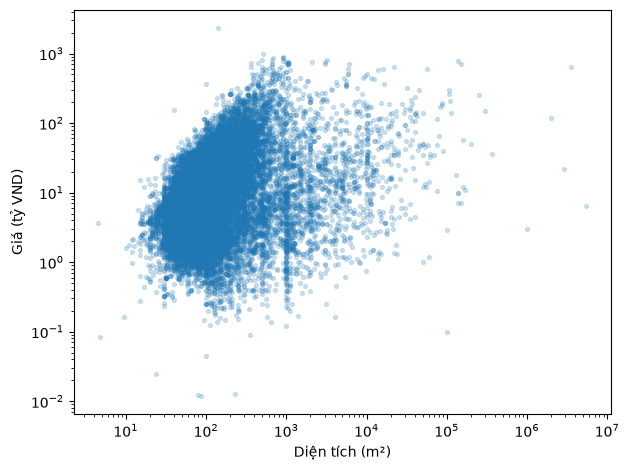

In [84]:
plt.scatter(data["area_sqm"], data["price_vnd"] / 1e9, alpha=0.2, s=8)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Diện tích (m²)")
plt.ylabel("Giá (tỷ VND)")
plt.tight_layout()
plt.show()

In [ ]:
train_df, test_df = train_test_split(data, test_size=0.2, random_state=42)
train_df, test_df = train_df.copy(), test_df.copy()
print("Train ban đầu:", train_df.shape, "| Test:", test_df.shape)
#tính log cho ppsm riêng tập train
train_df["log_price_sqm"] = np.log(train_df["price_vnd"] / train_df["area_sqm"])
group = train_df.groupby("province")["log_price_sqm"]
q1 = group.transform("quantile", 0.25)
q3 = group.transform("quantile", 0.75)

Train ban đầu: (28012, 10) | Test: (7004, 10)


In [ ]:
#tỉnh có count dưới 30 chung outlier
province_size = train_df["province"].map(train_df["province"].value_counts())
q1 = q1.where(province_size >= 30, train_df["log_price_sqm"].quantile(0.25))
q3 = q3.where(province_size >= 30, train_df["log_price_sqm"].quantile(0.75))
iqr = q3 - q1
keep = train_df["log_price_sqm"].between(q1 - 1.5 * iqr, q3 + 1.5 * iqr)
print("Outlier bị loại khỏi train:", int((~keep).sum()))

Outlier bị loại khỏi train: 765


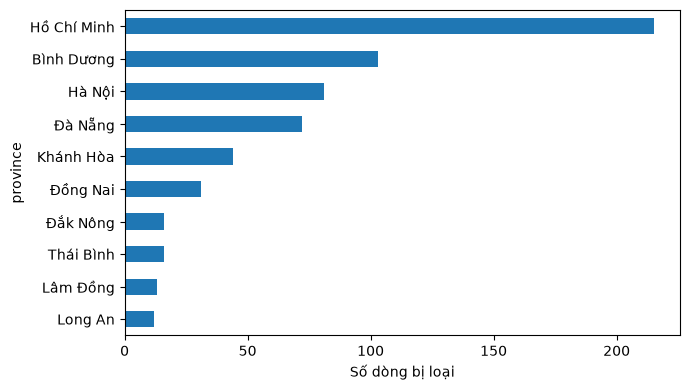

In [87]:
train_df.loc[~keep, "province"].value_counts().head(10).sort_values().plot(
    kind="barh", figsize=(7, 4)
)
plt.xlabel("Số dòng bị loại")
plt.tight_layout()
plt.show()

In [88]:
train_df = train_df.loc[keep].drop(columns="log_price_sqm").copy()
print("Train sau lọc:", train_df.shape, "| Test giữ nguyên:", test_df.shape)

Train sau lọc: (27247, 10) | Test giữ nguyên: (7004, 10)


In [ ]:
numeric_features = ["log_area_sqm", "bedrooms_num", "bathrooms_num"]
binary_features = ["property_type"]
categorical_features = ["province", "local_area"]
features = numeric_features + binary_features + categorical_features

X_train = train_df[features].copy()
X_test = test_df[features].copy()
#log giá tính bằng tỷ vnd
y_train = np.log1p(train_df["price_vnd"] / 1e9)
y_test = np.log1p(test_df["price_vnd"] / 1e9)
test_price = test_df["price_vnd"] / 1e9

In [90]:
numeric_process = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("polynomial", PolynomialFeatures(degree=3, include_bias=False))
])
category_process = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Không rõ")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [ ]:
preprocessor = ColumnTransformer([
    ("num", numeric_process, numeric_features),
    ("bin", "passthrough", binary_features),
    ("cat", category_process, categorical_features)
])
#fit tiền xử lý dữ liệu
X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)
print("X_train:", X_train.shape, "| X_test:", X_test.shape)

X_train: (27247, 412) | X_test: (7004, 412)


In [ ]:
#dùng Linear Regression của sklearn
model = LinearRegression()
model.fit(X_train, y_train)
pred_log = model.predict(X_test)
pred_price = np.maximum(np.expm1(pred_log), 0)
print("R² log-giá:", round(r2_score(y_test, pred_log), 3))
print("R² giá gốc:", round(r2_score(test_price, pred_price), 3))
print("MAE (tỷ VND):", round(mean_absolute_error(test_price, pred_price), 3))


R² log-giá: 0.705
R² giá gốc: 0.483
MAE (tỷ VND): 8.748
